# Caffeine & Sleep Time Planner (Set, Logic, Sequence)
**ปัญหา:** ช่วงสอบนักศึกษาดื่มกาแฟ แต่คาเฟอีนค้างในร่างกายหลายชั่วโมง ทำให้นอนไม่หลับ

**วัตถุประสงค์:** บอกว่าดื่มกาแฟแล้ว **นอนได้ตามเวลาที่ตั้งใจหรือไม่** และ **นอนได้ตั้งแต่กี่โมง**

## สูตร: คาเฟอีนลดลงครึ่งหนึ่งทุก 5 ชั่วโมง
$$C(t) = D \times \left(\tfrac{1}{2}\right)^{t/5}$$
$D$ = คาเฟอีนที่ดื่ม (mg), $t$ = ชั่วโมงหลังดื่ม · นอนได้เมื่อเหลือ **≤ 50 mg** · ไม่ควรดื่มเกิน **400 mg/วัน**

In [1]:
import matplotlib.pyplot as plt

SLEEP_LIMIT = 50   # mg
DAILY_LIMIT = 400  # mg

def caffeine_left(dose, hours):
    return dose * 0.5 ** (hours / 5)

def show_time(hour):          # 25 -> "01:00"
    return f"{hour % 24:02d}:00"

## หัวข้อที่ 1: Set (Lab 2)
- $A$ = ชั่วโมงที่คาเฟอีน ≤ 50 mg (**นอนได้**)
- $B$ = ชั่วโมงที่ **อยากนอน** (ตั้งแต่เข้านอนจนก่อนตื่น)
- $A \cap B$ = ชั่วโมงที่นอนได้จริง · $B - A$ = ชั่วโมงที่อยากนอนแต่ยังนอนไม่ได้

In [2]:
def make_sets(dose, drink, bed, wake):
    if bed < drink:        # นอนหลังเที่ยงคืน = วันถัดไป
        bed += 24
    while wake <= bed:     # ตื่นหลังเวลานอน
        wake += 24

    A = set()
    for h in range(drink, wake + 1):
        if caffeine_left(dose, h - drink) <= SLEEP_LIMIT:
            A.add(h)
    B = set(range(bed, wake))
    return A, B

## หัวข้อที่ 2: Logic (Lab 3)
- $p$: ช่วงที่อยากนอนปลอดภัยทั้งหมด ($B \subseteq A$)
- $q$: ดื่มไม่เกิน 400 mg
- **นอนได้ ⇔ $p \land q$** ถ้านอนไม่ได้ ดูว่า $\lnot p$ หรือ $\lnot q$ เป็นจริง

In [3]:
def check_sleep(dose, A, B):
    p = B <= A                 # B ⊆ A
    q = dose <= DAILY_LIMIT
    return p, q

## หัวข้อที่ 3: Sequence (Lab 4)
คาเฟอีนแต่ละชั่วโมงเป็น **ลำดับเรขาคณิต** (geometric sequence)

$$a_n = D \cdot r^n, \qquad r = 0.5^{1/5} \approx 0.87$$

- $D$ = คาเฟอีนที่ดื่ม (mg), $n$ = เวลานอน − เวลาดื่ม (ชั่วโมง)
- นอนได้เมื่อ $a_n \le 50$ ดังนั้น **ดื่มได้ไม่เกิน**

$$D \le \frac{50}{r^n}$$

และต้องไม่เกิน 400 mg/วัน

In [4]:
R = 0.5 ** (1 / 5)   # r ≈ 0.87

def max_dose(drink, bed):
    if bed < drink:          # นอนหลังเที่ยงคืน
        bed += 24
    n = bed - drink
    limit = SLEEP_LIMIT / R ** n
    return min(int(limit + 1e-9), DAILY_LIMIT)

In [5]:
def ask_number(text, low, high, input_fn=input):
    while True:
        user_input = input_fn(text)

        if not user_input.isdigit():
            print(f"กรุณากรอกเฉพาะจำนวน {low}-{high} และเท่านั้น")
            continue

        value = int(user_input)

        if low <= value <= high:
            return value
        else:
            print(f"กรุณากรอกเฉพาะจำนวน {low}-{high} เท่านั้น")

#แก้ให้เวลาสามารถเพิ่มจุดได้
def ask_time(text, input_fn=input):
    while True:
        user_input = input_fn(text).strip()

        try:
            # รองรับทั้ง 21.00 และ 21:00
            user_input = user_input.replace(".", ":")

            if ":" in user_input:
                parts = user_input.split(":")

                if len(parts) != 2:
                    raise ValueError

                hour = int(parts[0])
                minute = int(parts[1])

                # โปรเจกต์นี้คำนวณเป็นรายชั่วโมง
                if minute != 0:
                    raise ValueError

            else:
                hour = int(user_input)

            if 0 <= hour <= 23:
                return hour

        except ValueError:
            pass

        print("กรุณากรอกเวลา 0-23 เช่น 21, 21.00 หรือ 21:00")

def plan(dose, drink, bed, wake, show_plot=True):
    A, B = make_sets(dose, drink, bed, wake)
    p, q = check_sleep(dose, A, B)

    # User-friendly output
    if not p:
        print("\u274c คาเฟอีนยังเกิน 50 mg ตอนนอน")

    if not q:
        print("\u274c ดื่มเกิน 400 mg ต่อวัน")

    if p and q:
        print("\u2705 คุณสามารถนอนได้ตามเวลาที่ตั้งใจ")

    if A:
        print("\u23f0 นอนได้ตั้งแต่", show_time(min(A)))

    # Sequence
    print(f"\u2615 ถ้าจะนอน {show_time(bed)} ควรดื่มไม่เกิน {max_dose(drink, bed)} mg (ดื่มไป {dose} mg)")

    # กราฟ
    if show_plot:
        hours = list(range(drink, max(B) + 2))
        plt.plot(hours, [caffeine_left(dose, h - drink) for h in hours], marker="o", label="Caffeine")
        plt.axhline(SLEEP_LIMIT, color="red", linestyle="--", label="50 mg limit")
        plt.axvline(min(B), color="gray", linestyle=":", label="Bedtime")
        plt.xticks(hours, [show_time(h) for h in hours], rotation=60)
        plt.ylabel("Caffeine (mg)")
        plt.legend()
        plt.grid(True)
        plt.show()

    return p, q

def main():
    dose = ask_number("คาเฟอีนที่ดื่ม (mg): ", 1, 1000)
    drink = ask_time("เวลาที่ดื่ม (เช่น 21:00): ")
    bed = ask_time("เวลาที่อยากนอน (เช่น 23:00): ")
    wake = ask_time("เวลาที่ตื่น (เช่น 07:00): ")

    plan(dose, drink, bed, wake)


**สรุปผล:** กรณี 1 นอนได้ · กรณี 2 คาเฟอีนยังสูงตอน 23:00 ต้องรอถึง 01:00 · กรณี 3 คาเฟอีนลดทัน แต่ดื่มเกิน 400 mg

**Sequence:** ดื่มได้ไม่เกิน กรณี 1: 200 mg · กรณี 2: 75 mg (ดื่ม 96 จึงนอนไม่ได้) · กรณี 3: 400 mg (ติดเพดานต่อวัน)

**ข้อจำกัด:** ใช้ครึ่งชีวิต 5 ชม. เท่ากันทุกคน, ดื่มครั้งเดียว, คิดทีละชั่วโมง — เป็นค่าประมาณ ไม่ใช่คำแนะนำทางการแพทย์

## สาธิต: กรอกข้อมูลเอง

คาเฟอีนที่ดื่ม (mg):  200
เวลาที่ดื่ม (เช่น 21:00):  15
เวลาที่อยากนอน (เช่น 23:00):  20
เวลาที่ตื่น (เช่น 07:00):  06


❌ คาเฟอีนยังเกิน 50 mg ตอนนอน
⏰ นอนได้ตั้งแต่ 01:00
☕ ถ้าจะนอน 20:00 ควรดื่มไม่เกิน 100 mg (ดื่มไป 200 mg)


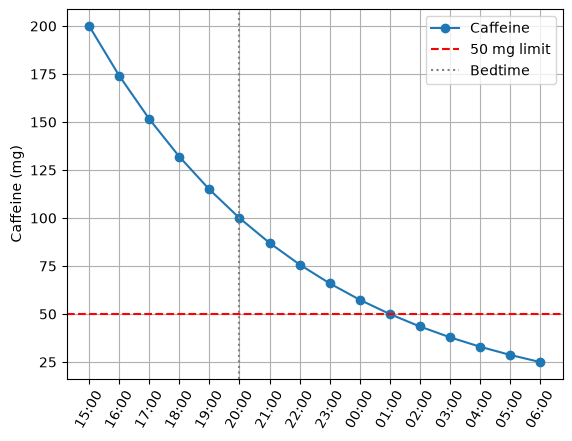

In [6]:
main()